# Parte 2: Clasificación de titulares peruanos

## Configuración inicial

- **Estudiante:** Diego Enrique Sime Rendón.
- **Insumo:** `datos/noticias.csv`: 400 noticias de La República, 100 por categoría (Parte 1).
- **Categorías:** `politica`, `economia`, `deportes`, `ciencia_tecnologia`.
- **Semilla:** `random_state=42` en todos los procesos aleatorios.

## Pregunta de esta etapa

¿Qué tan bien puede un modelo asignar un titular a una de las cuatro categorías,
y cuál conviene usar en producción considerando precisión, costo computacional y latencia?

## Decisiones metodológicas

| Decisión | Elección | Motivo |
|---|---|---|
| Texto de entrada | Solo `titular` | El probador del dashboard recibirá titulares sueltos; el modelo debe aprender con el mismo tipo de texto. |
| Etiqueta de referencia | `etiqueta` (sección del diario normalizada en la Parte 1) | La asignan los editores del medio. Es la referencia para entrenar, validar y evaluar. |
| Etiquetas del LLM | Supervisión débil: se guardan, se auditan y se comparan | Miden cuánto se acerca un etiquetador automático, sin entrenamiento, a la referencia. |
| Orden de los procesos | La partición se hace antes del zero-shot | El conjunto de prueba queda aislado desde el inicio y los tres modelos se comparan sobre titulares que ninguno usó para aprender. |

## Procesos previstos

0. Comprobar el entorno y definir la configuración.
1. Cargar y verificar la base.
2. Partición estratificada 70/15/15.
3. Línea base zero-shot sobre 40 titulares de prueba.
4. Etiquetas débiles con un LLM local y auditoría humana de 20 casos.
5. Fine-tuning de un Transformer.
6. Evaluación final en el conjunto de prueba.
7. Comparativa y decisión.

In [1]:
# PROCESO 0: Comprobar las herramientas del entorno.
# Insumo: entorno Python seleccionado (pucp).
# Resultado: listado de paquetes disponibles y faltantes.

# sys: identifica el Python que ejecuta este notebook.
import sys

# find_spec: comprueba si un paquete está instalado sin cargarlo.
from importlib.util import find_spec

print("Python:", sys.executable)

paquetes = {
    "torch": "torch",
    "transformers": "transformers",
    "datasets": "datasets",
    "accelerate": "accelerate",
    "scikit-learn": "sklearn",
    "seaborn": "seaborn",
}

faltantes = []
for nombre, modulo in paquetes.items():
    disponible = find_spec(modulo) is not None
    print(f"{nombre}: {'Disponible' if disponible else 'Falta instalar'}")
    if not disponible:
        faltantes.append(nombre)

if faltantes:
    print("\nInstala lo que falta con la celda siguiente y reinicia el kernel.")

Python: c:\Users\Diego Sime\.conda\envs\pucp\python.exe
torch: Disponible
transformers: Disponible
datasets: Disponible
accelerate: Disponible
scikit-learn: Disponible
seaborn: Disponible


In [2]:
# Instalar los paquetes de la Parte 2 en el entorno del notebook (solo una vez).
# torch en versión CPU: descarga más liviana; no requiere tarjeta gráfica.
# %pip install torch --index-url https://download.pytorch.org/whl/cpu
# %pip install "transformers>=4.56" datasets accelerate scikit-learn seaborn

In [3]:
# PROCESO 0.1: Definir rutas, semilla y modelos.
# Insumo: estructura de la carpeta tarea_1.
# Resultado: constantes compartidas por todos los procesos.

# os: ajusta variables de entorno antes de cargar Hugging Face.
import os

# Ocultar avisos de Windows sobre accesos directos en la caché de modelos.
os.environ.setdefault("HF_HUB_DISABLE_SYMLINKS_WARNING", "1")
# Evitar avisos de paralelismo del tokenizador dentro de Jupyter.
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")

# pathlib: localiza carpetas y archivos sin escribir rutas absolutas.
from pathlib import Path

# json: guarda métricas en un archivo liviano que leerá el dashboard.
import json

# time: mide cuánto tarda cada modelo (latencia y entrenamiento).
import time

# numpy: opera con vectores de puntajes y probabilidades.
import numpy as np

# pandas: organiza noticias, etiquetas y resultados en tablas.
import pandas as pd

# torch: motor de cálculo que ejecuta las redes neuronales.
import torch

# transformers: descarga y ejecuta modelos preentrenados de Hugging Face.
import transformers

# set_seed: fija las semillas de random, numpy y torch a la vez.
from transformers import set_seed

# Identificar la carpeta de la tarea según dónde se ejecute el notebook.
carpeta_actual = Path.cwd()
carpeta_tarea = (
    carpeta_actual if carpeta_actual.name == "tarea_1"
    else carpeta_actual / "tarea_1"
)

if not carpeta_tarea.is_dir():
    raise FileNotFoundError(
        f"No se encontró tarea_1. Carpeta actual: {carpeta_actual}"
    )

carpeta_datos = carpeta_tarea / "datos"
carpeta_modelo = carpeta_tarea / "modelo"
carpeta_modelo.mkdir(exist_ok=True)

SEMILLA = 42
CATEGORIAS = ["politica", "economia", "deportes", "ciencia_tecnologia"]

# Modelos de Hugging Face. Para probar otro, basta cambiar el identificador.
MODELO_ZERO_SHOT = "Recognai/bert-base-spanish-wwm-cased-xnli"
MODELO_LLM = "Qwen/Qwen2.5-1.5B-Instruct"
MODELO_BASE = "distilbert/distilbert-base-multilingual-cased"
# Alternativas: "joeddav/xlm-roberta-large-xnli" (zero-shot, 2,2 GB)
#               "dccuchile/bert-base-spanish-wwm-cased" (BETO, más lento en CPU)

# set_seed(): sin semilla → resultados distintos en cada ejecución;
#             con semilla → mismos resultados al volver a ejecutar.
set_seed(SEMILLA)

print("transformers:", transformers.__version__, "| torch:", torch.__version__)
print("Dispositivo:", "GPU" if torch.cuda.is_available() else "CPU")
print("Carpeta de la tarea:", carpeta_tarea)

c:\Users\Diego Sime\.conda\envs\pucp\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


transformers: 5.20.1 | torch: 2.14.1+cpu
Dispositivo: CPU
Carpeta de la tarea: d:\Mis Documentos\GitHub\Python-Intermedio-QLAB\tarea_1


## Proceso 1: Cargar y verificar la base

**Insumo:** `datos/noticias.csv`, exportado en la Parte 1.

**Resultado esperado:** 400 titulares únicos, cuatro categorías oficiales y una
columna numérica `label`, porque los modelos trabajan con números y no con textos.

In [4]:
# PROCESO 1: Cargar y verificar la base de noticias.
# Insumo: datos/noticias.csv.
# Resultado: tabla noticias con la columna numérica label.

noticias = pd.read_csv(
    carpeta_datos / "noticias.csv", encoding="utf-8-sig"
)

columnas_esperadas = [
    "titular", "bajada", "medio", "seccion_original",
    "url", "fecha", "etiqueta"
]

if list(noticias.columns) != columnas_esperadas:
    raise ValueError(f"Columnas inesperadas: {list(noticias.columns)}")

if noticias[["titular", "etiqueta"]].isna().any().any():
    raise ValueError("Hay titulares o etiquetas vacías.")

if noticias["titular"].duplicated().any():
    raise ValueError("Hay titulares repetidos.")

categorias_encontradas = set(noticias["etiqueta"])
if categorias_encontradas != set(CATEGORIAS):
    raise ValueError(
        "Las categorías no son las cuatro oficiales. "
        f"Sobran: {categorias_encontradas - set(CATEGORIAS)}. "
        "Corrige el mapeo en la Parte 1 y vuelve a exportar noticias.csv."
    )

# Diccionarios de traducción entre texto y número.
etiqueta_a_id = {categoria: i for i, categoria in enumerate(CATEGORIAS)}
id_a_etiqueta = {i: categoria for categoria, i in etiqueta_a_id.items()}

# map(): etiqueta en texto ("deportes") → número entero (2).
noticias["label"] = noticias["etiqueta"].map(etiqueta_a_id)

print("Dimensiones:", noticias.shape)
print("\nNoticias por categoría:")
print(noticias["etiqueta"].value_counts())
display(noticias[["titular", "etiqueta", "label"]].head())

Dimensiones: (400, 8)

Noticias por categoría:
etiqueta
ciencia_tecnologia    100
deportes              100
economia              100
politica              100
Name: count, dtype: int64


,titular,etiqueta,label
0,Los lobos gigantes modificados genéticamente p...,ciencia_tecnologia,3
1,"En 1986, la explosión del reactor de Chernóbil...",ciencia_tecnologia,3
2,Investigadores sudafricanos pintan franjas roj...,ciencia_tecnologia,3
3,En 1993 se liberaron 300 bisontes en una prade...,ciencia_tecnologia,3
4,Desconcertación entre los científicos: la Luna...,ciencia_tecnologia,3


## Proceso 2: Partición estratificada 70/15/15

**Método:** dos cortes con `train_test_split`. Primero 70 % para entrenamiento y
30 % restante; luego ese 30 % se divide por mitades en validación y prueba.

- **Entrenamiento (train):** el modelo aprende con estos titulares.
- **Validación (val):** elige la mejor época durante el entrenamiento.
- **Prueba (test):** queda aislada hasta la evaluación final.

`stratify` conserva el 25 % de cada categoría en los tres conjuntos.

In [5]:
# PROCESO 2: Dividir la base en entrenamiento, validación y prueba.
# Insumo: tabla noticias (400 filas).
# Resultado: tres tablas estratificadas y datos/particion.csv.

# train_test_split: divide una tabla al azar, con semilla y estratificación.
from sklearn.model_selection import train_test_split

# Primer corte: 400 noticias → 280 entrenamiento + 120 restantes.
entrenamiento, resto = train_test_split(
    noticias,
    test_size=0.30,
    stratify=noticias["etiqueta"],
    random_state=SEMILLA
)

# Segundo corte: 120 restantes → 60 validación + 60 prueba.
validacion, prueba = train_test_split(
    resto,
    test_size=0.50,
    stratify=resto["etiqueta"],
    random_state=SEMILLA
)

# reset_index(): índices desordenados del corte → índices 0, 1, 2...
entrenamiento = entrenamiento.reset_index(drop=True)
validacion = validacion.reset_index(drop=True)
prueba = prueba.reset_index(drop=True)

# Verificar que ningún titular aparezca en dos conjuntos.
conjuntos = [set(entrenamiento["titular"]), set(validacion["titular"]),
             set(prueba["titular"])]
if (conjuntos[0] & conjuntos[1]) or (conjuntos[0] & conjuntos[2]) \
        or (conjuntos[1] & conjuntos[2]):
    raise ValueError("Hay titulares compartidos entre conjuntos.")

# assign() + concat(): tres tablas → una sola con la columna conjunto.
particion = pd.concat([
    entrenamiento.assign(conjunto="train"),
    validacion.assign(conjunto="val"),
    prueba.assign(conjunto="test"),
], ignore_index=True)

# Guardar qué noticia quedó en cada conjunto, para trazabilidad.
particion[["url", "titular", "etiqueta", "conjunto"]].to_csv(
    carpeta_datos / "particion.csv", index=False, encoding="utf-8-sig"
)

# crosstab(): filas individuales → conteo por categoría y conjunto.
display(pd.crosstab(
    particion["etiqueta"], particion["conjunto"], margins=True,
    margins_name="total"
)[["train", "val", "test", "total"]])

conjunto,train,val,test,total
etiqueta,,,,
ciencia_tecnologia,70,15,15,100
deportes,70,15,15,100
economia,70,15,15,100
politica,70,15,15,100
total,280,60,60,400


## Proceso 3: Línea base zero-shot

**Método:** un modelo entrenado en *inferencia de lenguaje natural* (NLI) recibe el
titular y una hipótesis por categoría, por ejemplo *"Esta noticia trata sobre deportes."*
La categoría cuya hipótesis resulta más compatible con el titular es la predicción.
No hay entrenamiento con nuestros datos.

**Insumo:** 40 titulares del conjunto de prueba, 10 por categoría.

**Resultado esperado:** accuracy y F1 macro. Es el **piso** que el modelo final debe superar.

**Por qué F1 macro:** promedia el F1 de cada categoría con el mismo peso, de modo
que una categoría mal clasificada no queda oculta por las demás.

In [6]:
# PROCESO 3: Medir la línea base zero-shot.
# Insumo: 40 titulares de prueba y el modelo NLI.
# Resultado: predicciones, accuracy, F1 macro y latencia del zero-shot.

# pipeline: reúne tokenizador, modelo y postproceso en una sola función.
from transformers import pipeline

# accuracy_score y f1_score: comparan etiquetas reales y predichas → número entre 0 y 1.
from sklearn.metrics import accuracy_score, f1_score

# groupby().sample(): 60 titulares de prueba → 40 (10 por categoría).
muestra_zs = (
    prueba.groupby("etiqueta", group_keys=False)
    .sample(n=10, random_state=SEMILLA)
    .reset_index(drop=True)
)

# El modelo NLI entiende frases en español, no códigos como "ciencia_tecnologia".
descripciones_zs = {
    "política": "politica",
    "economía": "economia",
    "deportes": "deportes",
    "ciencia y tecnología": "ciencia_tecnologia",
}

clasificador_zs = pipeline(
    "zero-shot-classification", model=MODELO_ZERO_SHOT
)

predicciones_zs = []
confianzas_zs = []

inicio = time.perf_counter()
for titular in muestra_zs["titular"]:
    # clasificador_zs(): titular → categorías ordenadas de mayor a menor puntaje.
    resultado = clasificador_zs(
        titular,
        candidate_labels=list(descripciones_zs),
        hypothesis_template="Esta noticia trata sobre {}."
    )
    # La primera categoría es la de mayor puntaje → se traduce al código oficial.
    predicciones_zs.append(descripciones_zs[resultado["labels"][0]])
    confianzas_zs.append(resultado["scores"][0])

latencia_zs = 1000 * (time.perf_counter() - inicio) / len(muestra_zs)

muestra_zs["pred_zero_shot"] = predicciones_zs
muestra_zs["confianza_zero_shot"] = confianzas_zs

acc_zs = accuracy_score(muestra_zs["etiqueta"], muestra_zs["pred_zero_shot"])
f1_zs = f1_score(
    muestra_zs["etiqueta"], muestra_zs["pred_zero_shot"], average="macro"
)
parametros_zs = clasificador_zs.model.num_parameters()

print(f"Zero-shot ({MODELO_ZERO_SHOT}) sobre {len(muestra_zs)} titulares")
print(f"Accuracy: {acc_zs:.3f} | F1 macro: {f1_zs:.3f}")
print(f"Latencia: {latencia_zs:.0f} ms por titular")

display(pd.crosstab(
    muestra_zs["etiqueta"], muestra_zs["pred_zero_shot"],
    rownames=["real"], colnames=["zero-shot"]
))

# Errores: insumo para explicar por qué falla la línea base.
errores_zs = muestra_zs.loc[
    muestra_zs["etiqueta"] != muestra_zs["pred_zero_shot"],
    ["titular", "etiqueta", "pred_zero_shot", "confianza_zero_shot"]
]
with pd.option_context("display.max_colwidth", None):
    display(errores_zs)

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 957.71it/s] 


Zero-shot (Recognai/bert-base-spanish-wwm-cased-xnli) sobre 40 titulares
Accuracy: 0.650 | F1 macro: 0.639
Latencia: 169 ms por titular


zero-shot,ciencia_tecnologia,deportes,economia,politica
real,,,,
ciencia_tecnologia,6,0,3,1
deportes,0,9,0,1
economia,1,2,4,3
politica,1,2,0,7


,titular,etiqueta,pred_zero_shot,confianza_zero_shot
0,El desierto de Atacama en Chile está repleto de brillantes flores silvestres gracias al fenómeno Súper El Niño: más de 200 especies de plantas,ciencia_tecnologia,economia,0.341382
4,Ni en el refrigerador ni en el frutero: este es el lugar donde deben guardarse los plátanos para que no se oscurezcan tan rápido,ciencia_tecnologia,economia,0.622126
5,"China levantó una muralla de árboles contra el desierto y, casi 50 años después, el plan amenaza sus reservas de agua",ciencia_tecnologia,politica,0.339897
9,"El ambicioso proyecto que busca generar electricidad con el océano para 32.000 hogares, alimentar centros de IA y producir agua potable",ciencia_tecnologia,economia,0.376432
19,"Mamá de Cristiano Ronaldo envía duro mensaje contra Portugal: ""No lo valoran, es el pueblo que tenemos""",deportes,politica,0.720008
20,Trabajo presencial: 49% de peruanos rechazó una oferta laboral por exigir presencialidad,economia,politica,0.522389
22,Ecuador evalúa procesar parte de su crudo en refinerías de Perú,economia,ciencia_tecnologia,0.288445
24,"BCRP reduce crecimiento de Perú a 3,2% en 2026 por mayor golpe de El Niño",economia,deportes,0.332969
26,"Petroperú mejora sus resultados financieros, pero sindicato cuestiona intervención de ProInversión",economia,politica,0.637787
28,Sueldo mínimo: Sheput anuncia primer aumento de S/100 y revela que el segundo de S/70 se dará el próximo año,economia,deportes,0.391804


## Proceso 4: Etiquetas débiles con un LLM local

**Modelo:** `Qwen/Qwen2.5-1.5B-Instruct`, un LLM abierto que corre en la propia
computadora (sin API key ni costo por consulta). Es de la misma familia que el
modelo usado en la sesión 08 del curso. La primera vez descarga unos 3 GB.

**Prompt estructurado:** rol, tarea, definición de cada categoría, reglas y formato de respuesta.

**Cómo se obtiene la etiqueta y la confianza:** en lugar de dejar que el modelo
escriba texto libre, se lee su distribución del **siguiente token** (sesión 08) y se
comparan solo las cuatro categorías. Así la respuesta siempre es válida y la
`confianza` es la probabilidad asignada a la categoría elegida.

**Resultado esperado:** `datos/etiquetas_llm.csv` con las columnas
`titular`, `etiqueta_llm`, `confianza`, `modelo_llm`, `fecha` y una auditoría humana de 20 casos.

In [7]:
# PROCESO 4.1: Cargar el LLM y definir el prompt estructurado.
# Insumo: identificador MODELO_LLM.
# Resultado: función etiquetar_con_llm, probada con cuatro titulares.

# AutoTokenizer: convierte texto en números (tokens) y viceversa.
# AutoModelForCausalLM: modelo generativo que predice el siguiente token.
from transformers import AutoTokenizer, AutoModelForCausalLM

tokenizador_llm = AutoTokenizer.from_pretrained(MODELO_LLM)

# Relleno a la izquierda: el último token de cada fila es texto real, no relleno.
tokenizador_llm.padding_side = "left"

# float32: formato numérico que la CPU procesa con mayor rapidez.
modelo_llm = AutoModelForCausalLM.from_pretrained(
    MODELO_LLM, dtype=torch.float32
)
modelo_llm.eval()

INSTRUCCIONES = """Eres editor de un diario peruano y clasificas titulares de noticias.

Categorías permitidas:
- politica: gobierno, Congreso, elecciones, partidos, autoridades, justicia, seguridad ciudadana y relaciones internacionales.
- economia: mercados, empresas, precios, empleo, impuestos, tipo de cambio, comercio, minería y finanzas.
- deportes: fútbol, vóley y otras competencias, deportistas, clubes y selecciones.
- ciencia_tecnologia: investigación científica, salud, medio ambiente, animales, espacio, arqueología, inventos y tecnología.

Reglas:
1. Elige exactamente una categoría.
2. Si el titular menciona varios temas, elige el tema principal.
3. Responde solo con el nombre de la categoría, sin explicaciones."""

# encode(): nombre de la categoría → lista de tokens; se usa el primero de cada una.
ids_categorias = [
    tokenizador_llm.encode(categoria, add_special_tokens=False)[0]
    for categoria in CATEGORIAS
]

if len(set(ids_categorias)) != len(CATEGORIAS):
    raise ValueError("Dos categorías comienzan con el mismo token.")


def construir_prompt(titular):
    """Titular (texto) → conversación en el formato de chat del modelo (texto)."""
    mensajes = [
        {"role": "system", "content": INSTRUCCIONES},
        {"role": "user", "content": f"Titular: {titular}\nCategoría:"},
    ]
    return tokenizador_llm.apply_chat_template(
        mensajes, tokenize=False, add_generation_prompt=True
    )


@torch.no_grad()
def etiquetar_con_llm(titulares, tamano_lote=8):
    """Lista de titulares → tabla con etiqueta_llm y confianza (0 a 1)."""
    filas = []

    for inicio in range(0, len(titulares), tamano_lote):
        lote = list(titulares[inicio:inicio + tamano_lote])

        # tokenizador_llm(): textos → tensores de números del mismo largo.
        entradas = tokenizador_llm(
            [construir_prompt(titular) for titular in lote],
            return_tensors="pt", padding=True
        )

        # logits[:, -1, :]: puntaje de cada token posible como siguiente palabra.
        logits = modelo_llm(**entradas).logits[:, -1, :]

        # softmax(): 4 puntajes de las categorías → 4 probabilidades que suman 1.
        probabilidades = torch.softmax(logits[:, ids_categorias], dim=-1)

        for titular, fila in zip(lote, probabilidades):
            indice = int(fila.argmax())
            filas.append({
                "titular": titular,
                "etiqueta_llm": CATEGORIAS[indice],
                "confianza": round(float(fila[indice]), 4),
            })

    return pd.DataFrame(filas)


# Probar con un titular por categoría antes de procesar los 400.
ejemplos = noticias.groupby("etiqueta").head(1)
display(
    etiquetar_con_llm(ejemplos["titular"].tolist())
    .assign(etiqueta_seccion=ejemplos["etiqueta"].values)
)

Loading weights: 100%|██████████| 338/338 [00:08<00:00, 38.52it/s]


,titular,etiqueta_llm,confianza,etiqueta_seccion
0,Los lobos gigantes modificados genéticamente p...,ciencia_tecnologia,0.9913,ciencia_tecnologia
1,Alianza Lima vs Rebaza Acosta EN VIVO: punto a...,deportes,0.9996,deportes
2,"Petroperú mejora sus resultados financieros, p...",economia,0.9992,economia
3,Comisión de Constitución del Senado continuará...,politica,0.9937,politica


In [8]:
# PROCESO 4.2: Etiquetar las 400 noticias con el LLM.
# Insumo: titulares de noticias y función etiquetar_con_llm.
# Resultado: datos/etiquetas_llm.csv y latencia del LLM.

# date: registra la fecha en que se generaron las etiquetas.
from datetime import date

archivo_llm = carpeta_datos / "etiquetas_llm.csv"

# False: reutiliza etiquetas_llm.csv si ya existe (ahorra varios minutos).
# True: vuelve a etiquetar; úsalo si cambias el prompt o el modelo.
RECALCULAR_LLM = False

if archivo_llm.exists() and not RECALCULAR_LLM:
    etiquetas_llm = pd.read_csv(archivo_llm, encoding="utf-8-sig")
    print("Etiquetas recuperadas de:", archivo_llm)
else:
    inicio = time.perf_counter()
    etiquetas_llm = etiquetar_con_llm(noticias["titular"].tolist())
    print(f"Etiquetado en {(time.perf_counter() - inicio) / 60:.1f} minutos")

    etiquetas_llm["modelo_llm"] = MODELO_LLM
    # fecha: día en que el LLM generó la etiqueta (la fecha de la noticia está en noticias.csv).
    etiquetas_llm["fecha"] = date.today().isoformat()

    etiquetas_llm = etiquetas_llm[
        ["titular", "etiqueta_llm", "confianza", "modelo_llm", "fecha"]
    ]
    etiquetas_llm.to_csv(archivo_llm, index=False, encoding="utf-8-sig")
    print("Archivo guardado:", archivo_llm)

if set(etiquetas_llm["titular"]) != set(noticias["titular"]):
    raise ValueError("etiquetas_llm.csv no corresponde a noticias.csv; usa RECALCULAR_LLM = True.")

# Latencia: los 40 titulares del zero-shot, de uno en uno, como en el dashboard.
inicio = time.perf_counter()
for titular in muestra_zs["titular"]:
    etiquetar_con_llm([titular], tamano_lote=1)
latencia_llm = 1000 * (time.perf_counter() - inicio) / len(muestra_zs)
parametros_llm = modelo_llm.num_parameters()

print("Dimensiones:", etiquetas_llm.shape)
print(f"Latencia: {latencia_llm:.0f} ms por titular")
display(etiquetas_llm.head())

Etiquetas recuperadas de: d:\Mis Documentos\GitHub\Python-Intermedio-QLAB\tarea_1\datos\etiquetas_llm.csv
Dimensiones: (400, 5)
Latencia: 3158 ms por titular


,titular,etiqueta_llm,confianza,modelo_llm,fecha
0,Los lobos gigantes modificados genéticamente p...,ciencia_tecnologia,0.9913,Qwen/Qwen2.5-1.5B-Instruct,2026-10-18
1,"En 1986, la explosión del reactor de Chernóbil...",ciencia_tecnologia,0.9773,Qwen/Qwen2.5-1.5B-Instruct,2026-10-18
2,Investigadores sudafricanos pintan franjas roj...,ciencia_tecnologia,0.8781,Qwen/Qwen2.5-1.5B-Instruct,2026-10-18
3,En 1993 se liberaron 300 bisontes en una prade...,economia,0.5083,Qwen/Qwen2.5-1.5B-Instruct,2026-10-18
4,Desconcertación entre los científicos: la Luna...,ciencia_tecnologia,1.0000,Qwen/Qwen2.5-1.5B-Instruct,2026-10-18


In [9]:
# PROCESO 4.3: Comparar las etiquetas del LLM con las secciones del diario.
# Insumo: etiquetas_llm y noticias.
# Resultado: acuerdo global, matriz de cruce y métricas del LLM en prueba.

# merge(): dos tablas unidas por titular → una tabla con ambas etiquetas.
comparacion_llm = noticias[["titular", "etiqueta"]].merge(
    etiquetas_llm[["titular", "etiqueta_llm", "confianza"]],
    on="titular", how="left", validate="one_to_one"
)
comparacion_llm["coincide"] = (
    comparacion_llm["etiqueta"] == comparacion_llm["etiqueta_llm"]
)

print(f"Acuerdo LLM vs. sección en las 400 noticias: "
      f"{comparacion_llm['coincide'].mean():.1%}")

display(pd.crosstab(
    comparacion_llm["etiqueta"], comparacion_llm["etiqueta_llm"],
    rownames=["sección"], colnames=["LLM"]
))

# ¿El LLM está menos seguro cuando se equivoca?
print("\nConfianza promedio del LLM:")
print(comparacion_llm.groupby("coincide")["confianza"].mean().round(3)
      .rename({True: "cuando coincide", False: "cuando difiere"}))

# Métricas del LLM en los 60 titulares de prueba: mismo conjunto que el modelo final.
llm_prueba = prueba.merge(
    etiquetas_llm[["titular", "etiqueta_llm"]], on="titular", how="left"
)
acc_llm_test = accuracy_score(llm_prueba["etiqueta"], llm_prueba["etiqueta_llm"])
f1_llm_test = f1_score(
    llm_prueba["etiqueta"], llm_prueba["etiqueta_llm"], average="macro"
)
print(f"\nLLM en prueba (60): accuracy {acc_llm_test:.3f} | F1 macro {f1_llm_test:.3f}")

# Liberar unos 6 GB de memoria antes del entrenamiento.
# Para volver a usar el LLM, ejecuta otra vez el Proceso 4.1.
# gc: recolector de basura; elimina de la RAM los objetos ya borrados.
import gc

del modelo_llm
gc.collect()

Acuerdo LLM vs. sección en las 400 noticias: 85.5%


LLM,ciencia_tecnologia,deportes,economia,politica
sección,,,,
ciencia_tecnologia,83,2,15,0
deportes,0,80,0,20
economia,2,0,85,13
politica,1,0,5,94



Confianza promedio del LLM:
coincide
cuando difiere     0.713
cuando coincide    0.937
Name: confianza, dtype: float64

LLM en prueba (60): accuracy 0.767 | F1 macro 0.768


40

In [10]:
# PROCESO 4.4: Seleccionar 20 predicciones al azar para la auditoría.
# Insumo: etiquetas_llm.
# Resultado: tabla numerada de 20 titulares para revisar a mano.

# sample(): 400 predicciones → 20 al azar, siempre las mismas por la semilla.
auditoria = (
    etiquetas_llm.sample(n=20, random_state=SEMILLA)
    .reset_index(drop=True)
)
auditoria.insert(0, "n", range(1, len(auditoria) + 1))

with pd.option_context("display.max_colwidth", None):
    display(auditoria[["n", "titular", "etiqueta_llm", "confianza"]])

,n,titular,etiqueta_llm,confianza
0,1,"Perú recibió 2,26 millones de turistas extranjeros hasta agosto, 0,4% menos que en 2025",economia,0.9914
1,2,Sueldo mínimo: Sheput anuncia primer aumento de S/100 y revela que el segundo de S/70 se dará el próximo año,economia,0.9975
2,3,Buenas noticias para la ciencia en América Latina: un país ingresa a una red mundial que investiga el clima y los océanos de la Antártida,ciencia_tecnologia,0.9999
3,4,"Economía peruana creció 3,23% en agosto, pero minería y pesca retrocedieron",economia,0.9999
4,5,Un paleontólogo aficionado encontró el fósil casi completo de un titanosaurio de 10 metros de altura mientras paseaba con su perro,ciencia_tecnologia,0.8286
5,6,"La humanidad roza sus límites: la población mundial alcanzaría los 12.400 millones en 2070, mientras científicos sugieren reducirla a 4.000 millones para 2200",economia,0.5300
6,7,Comisión de Constitución del Senado EN VIVO: congresistas retoman debaten sobre dictamen de delegación de facultades,politica,0.9940
7,8,"El ambicioso proyecto que busca generar electricidad con el océano para 32.000 hogares, alimentar centros de IA y producir agua potable",economia,0.7492
8,9,Facultades legislativas: GEPS cuestiona pedido del Ejecutivo por falta de precisión en cambios tributarios y laborales,politica,0.8411
9,10,Universitario - Palmeiras: a qué hora y dónde ver el partido por la fecha 1 de la Copa Libertadores Femenina 2026,deportes,0.9996


In [23]:
# PROCESO 4.5: Registrar la revisión humana y calcular el acuerdo.
# Insumo: tabla de auditoría y tu criterio como lector.
# Resultado: acuerdo LLM–humano y datos/auditoria_llm.csv.

# COMPLETAR A MANO: lee cada titular de la tabla anterior y escribe la categoría
# que TÚ le asignarías. Valores permitidos: politica, economia, deportes, ciencia_tecnologia.
revision_humana = {
    1: "economia",
    2: "economia",
    3: "ciencia_tecnologia",
    4: "economia",
    5: "ciencia_tecnologia",
    6: "ciencia_tecnologia",
    7: "politica",
    8: "ciencia_tecnologia",
    9: "politica",
    10: "deportes",
    11: "ciencia_tecnologia",
    12: "politica",
    13: "ciencia_tecnologia",
    14: "ciencia_tecnologia",
    15: "deportes",
    16: "ciencia_tecnologia",
    17: "economia",
    18: "politica",
    19: "economia",
    20: "politica",
}

invalidas = [n for n, valor in revision_humana.items()
             if valor and valor not in CATEGORIAS]
if invalidas:
    raise ValueError(f"Categorías no válidas en las filas: {invalidas}")

pendientes = [n for n, valor in revision_humana.items() if not valor]

if pendientes:
    acuerdo_llm_humano = None
    aciertos_auditoria = None
    print(f"AUDITORÍA PENDIENTE: faltan {len(pendientes)} de 20 filas.")
    print("Completa revision_humana y vuelve a ejecutar esta celda.")
else:
    # map(): número de fila → etiqueta escrita por la persona revisora.
    auditoria["etiqueta_humana"] = auditoria["n"].map(revision_humana)
    auditoria["coincide"] = (
        auditoria["etiqueta_llm"] == auditoria["etiqueta_humana"]
    )

    aciertos_auditoria = int(auditoria["coincide"].sum())
    acuerdo_llm_humano = aciertos_auditoria / len(auditoria)

    print(f"Acuerdo LLM–humano: {aciertos_auditoria}/20 = {acuerdo_llm_humano:.0%}")

    with pd.option_context("display.max_colwidth", None):
        display(auditoria.loc[
            ~auditoria["coincide"],
            ["n", "titular", "etiqueta_llm", "etiqueta_humana", "confianza"]
        ])

    auditoria.to_csv(
        carpeta_datos / "auditoria_llm.csv", index=False, encoding="utf-8-sig"
    )

Acuerdo LLM–humano: 17/20 = 85%


,n,titular,etiqueta_llm,etiqueta_humana,confianza
5,6,"La humanidad roza sus límites: la población mundial alcanzaría los 12.400 millones en 2070, mientras científicos sugieren reducirla a 4.000 millones para 2200",economia,ciencia_tecnologia,0.5300
7,8,"El ambicioso proyecto que busca generar electricidad con el océano para 32.000 hogares, alimentar centros de IA y producir agua potable",economia,ciencia_tecnologia,0.7492
11,12,"Papa León XIV fue operado con éxito de nódulo en el pulmón, informó el Vaticano",ciencia_tecnologia,politica,0.6704


### Interpretación de la auditoría

Acuerdo LLM–humano: **17/20 (85 %)**. Las 3 discrepancias siguen un mismo patrón: el LLM decide por el
vocabulario y la persona por el contexto.
- Filas 6 (población mundial) y 8 (electricidad con el océano): las cifras y los "hogares" llevan al
  LLM a economía, pero son noticias de ciencia.
- Fila 12 (operación del Papa): "nódulo en el pulmón" lleva al LLM a ciencia (salud); el diario y la
  revisión humana la ubican en política (Vaticano).

En los tres casos la confianza del LLM fue baja (0,53–0,75), frente a 0,94 cuando coincide con la sección.

## Proceso 5: Fine-tuning del Transformer

**Modelo base:** `distilbert-base-multilingual-cased`. Es una versión reducida de BERT
(6 capas en lugar de 12) que entiende español y entrena en minutos en una CPU.

**Qué cambia en el modelo:** se le añade una capa final de 4 salidas (una por categoría)
y se ajustan todos sus pesos con los 280 titulares de entrenamiento.

| Parámetro | Valor | Motivo |
|---|---|---|
| Épocas | 3 | Mínimo pedido; cada época recorre los 280 titulares una vez. |
| Tamaño de lote | 8 | Dentro del rango 8–16; más actualizaciones de pesos con pocos datos. |
| Tasa de aprendizaje | 5e-5 | Valor habitual para ajustar modelos tipo BERT. |
| Longitud máxima | 64 tokens | Se verifica abajo que ningún titular se corte. |
| Evaluación | Al final de cada época, en validación | Se conserva la época con mayor F1 macro. |

In [12]:
# PROCESO 5.1: Convertir los titulares en tokens.
# Insumo: tablas entrenamiento, validacion y prueba.
# Resultado: tres Dataset tokenizados y verificación de longitudes.

# datasets: formato de tabla que el Trainer de Hugging Face recorre por lotes.
from datasets import Dataset

# AutoTokenizer: carga el tokenizador que corresponde al modelo base.
from transformers import AutoTokenizer

tokenizador = AutoTokenizer.from_pretrained(MODELO_BASE)

MAX_TOKENS = 64

# Verificar cuántos tokens ocupa cada titular antes de fijar MAX_TOKENS.
longitudes = [
    len(ids) for ids in tokenizador(noticias["titular"].tolist())["input_ids"]
]
print(f"Tokens por titular: mediana {np.median(longitudes):.0f}, "
      f"máximo {max(longitudes)}")
print("Titulares que se cortarían:", sum(n > MAX_TOKENS for n in longitudes))


def tokenizar(lote):
    """{'titular': textos} → {'input_ids', 'attention_mask'}: números de hasta MAX_TOKENS."""
    return tokenizador(lote["titular"], truncation=True, max_length=MAX_TOKENS)


def a_dataset(tabla):
    """DataFrame (titular, label) → Dataset tokenizado listo para el Trainer."""
    return (
        Dataset.from_pandas(tabla[["titular", "label"]], preserve_index=False)
        .map(tokenizar, batched=True, remove_columns=["titular"])
    )


ds_entrenamiento = a_dataset(entrenamiento)
ds_validacion = a_dataset(validacion)
ds_prueba = a_dataset(prueba)

print("\nEntrenamiento:", ds_entrenamiento)
print("Ejemplo tokenizado:",
      tokenizador.convert_ids_to_tokens(ds_entrenamiento[0]["input_ids"])[:15])

Tokens por titular: mediana 28, máximo 42
Titulares que se cortarían: 0


Map: 100%|██████████| 60/60 [00:00<00:00, 5984.03 examples/s]


Entrenamiento: Dataset({
    features: ['label', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 280
})
Ejemplo tokenizado: ['[CLS]', 'Los', 'primeros', 'animales', 'podrían', 'haber', 'evo', '##lu', '##cionado', 'mucho', 'antes', 'de', 'lo', 'que', 'su']


In [13]:
# PROCESO 5.2: Entrenar el modelo con el Trainer de Hugging Face.
# Insumo: modelo base y Dataset de entrenamiento y validación.
# Resultado: modelo ajustado e historial de métricas por época.

# AutoModelForSequenceClassification: modelo base + capa final de 4 categorías.
# DataCollatorWithPadding: iguala el largo de los titulares dentro de cada lote.
# TrainingArguments y Trainer: configuran y ejecutan el ciclo de entrenamiento.
from transformers import (
    AutoModelForSequenceClassification,
    DataCollatorWithPadding,
    TrainingArguments,
    Trainer,
)

# Aviso esperado: "Some weights ... newly initialized". Es la capa nueva de 4 salidas.
modelo = AutoModelForSequenceClassification.from_pretrained(
    MODELO_BASE,
    num_labels=len(CATEGORIAS),
    id2label=id_a_etiqueta,
    label2id=etiqueta_a_id,
)


def calcular_metricas(evaluacion):
    """(puntajes del modelo, etiquetas reales) → accuracy y F1 macro de la época."""
    logits, etiquetas = evaluacion
    # argmax(): 4 puntajes por titular → índice de la categoría con mayor puntaje.
    predicciones = np.argmax(logits, axis=-1)
    return {
        "accuracy": accuracy_score(etiquetas, predicciones),
        "f1_macro": f1_score(etiquetas, predicciones, average="macro"),
    }


argumentos = TrainingArguments(
    output_dir=str(carpeta_modelo / "checkpoints"),
    num_train_epochs=3,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=16,
    learning_rate=5e-5,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=1,
    load_best_model_at_end=True,
    metric_for_best_model="f1_macro",
    greater_is_better=True,
    logging_strategy="epoch",
    report_to="none",
    # Sin GPU, la memoria fijada no aporta nada y solo genera avisos.
    dataloader_pin_memory=False,
    seed=SEMILLA,
)

entrenador = Trainer(
    model=modelo,
    args=argumentos,
    train_dataset=ds_entrenamiento,
    eval_dataset=ds_validacion,
    processing_class=tokenizador,
    data_collator=DataCollatorWithPadding(tokenizador),
    compute_metrics=calcular_metricas,
)

inicio = time.perf_counter()
entrenador.train()
minutos_entrenamiento = (time.perf_counter() - inicio) / 60
print(f"\nEntrenamiento completado en {minutos_entrenamiento:.1f} minutos")

# log_history: registros sueltos del entrenamiento → una fila por época.
historial = pd.DataFrame(entrenador.state.log_history)
perdida = historial.dropna(subset=["loss"])[["epoch", "loss"]]
evaluacion = historial.dropna(subset=["eval_f1_macro"])[
    ["epoch", "eval_loss", "eval_accuracy", "eval_f1_macro"]
]
display(perdida.merge(evaluacion, on="epoch").round(4))

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 888.03it/s]
[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-multilingual-cased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro
1,0.871396,0.289933,0.916667,0.916551
2,0.154053,0.229907,0.933333,0.933259
3,0.071226,0.188726,0.950000,0.949495


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  2.82it/s]



Entrenamiento completado en 1.4 minutos


,epoch,loss,eval_loss,eval_accuracy,eval_f1_macro
0,1.0,0.8714,0.2899,0.9167,0.9166
1,2.0,0.1541,0.2299,0.9333,0.9333
2,3.0,0.0712,0.1887,0.9500,0.9495


In [14]:
# PROCESO 5.3: Guardar el modelo para el dashboard.
# Insumo: mejor modelo según F1 macro en validación.
# Resultado: carpeta modelo/ con pesos, configuración y tokenizador.

# shutil: borra carpetas completas; aquí, los puntos de control intermedios.
import shutil

# save_model(): modelo en memoria → archivos en modelo/ (incluye el tokenizador).
entrenador.save_model(str(carpeta_modelo))

# Los checkpoints solo sirven durante el entrenamiento y pesan más de 1 GB.
shutil.rmtree(carpeta_modelo / "checkpoints", ignore_errors=True)

print("Archivos en modelo/:")
for archivo in sorted(carpeta_modelo.iterdir()):
    if archivo.is_file():
        print(f"  {archivo.name}: {archivo.stat().st_size / 1e6:.1f} MB")
print("\nLos archivos .safetensors y .bin están excluidos en .gitignore (GitHub rechaza > 100 MB).")

Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  2.85it/s]

Archivos en modelo/:
  config.json: 0.0 MB
  model.safetensors: 541.3 MB
  tokenizer.json: 2.9 MB
  tokenizer_config.json: 0.0 MB
  training_args.bin: 0.0 MB

Los archivos .safetensors y .bin están excluidos en .gitignore (GitHub rechaza > 100 MB).


## Proceso 6: Evaluación final en el conjunto de prueba

**Insumo:** los 60 titulares de prueba que el modelo no vio al entrenar ni al elegir la época.

**Resultado esperado:** accuracy, F1 macro, reporte por categoría y matriz de confusión.

In [15]:
# PROCESO 6.1: Predecir el conjunto de prueba.
# Insumo: modelo guardado y ds_prueba.
# Resultado: accuracy, F1 macro y reporte por categoría.

# classification_report: etiquetas reales y predichas → precisión, recall y F1 por categoría.
from sklearn.metrics import classification_report

# predict(): 60 titulares tokenizados → matriz de puntajes de 60 × 4.
salida_prueba = entrenador.predict(ds_prueba)
ids_predichos = salida_prueba.predictions.argmax(axis=-1)

# Traducir números a categorías: 2 → "deportes".
prueba["pred_finetuned"] = [id_a_etiqueta[i] for i in ids_predichos]

acc_ft = accuracy_score(prueba["etiqueta"], prueba["pred_finetuned"])
f1_ft = f1_score(prueba["etiqueta"], prueba["pred_finetuned"], average="macro")

print(f"Transformer fine-tuned en prueba (60): accuracy {acc_ft:.3f} | F1 macro {f1_ft:.3f}\n")
print(classification_report(
    prueba["etiqueta"], prueba["pred_finetuned"],
    labels=CATEGORIAS, digits=3, zero_division=0
))

# Latencia: cargar el modelo desde modelo/, como lo hará app.py.
clasificador_final = pipeline("text-classification", model=str(carpeta_modelo))

inicio = time.perf_counter()
for titular in muestra_zs["titular"]:
    clasificador_final(titular)
latencia_ft = 1000 * (time.perf_counter() - inicio) / len(muestra_zs)
parametros_ft = entrenador.model.num_parameters()
print(f"Latencia: {latencia_ft:.0f} ms por titular")

Transformer fine-tuned en prueba (60): accuracy 0.950 | F1 macro 0.949

                    precision    recall  f1-score   support

          politica      1.000     0.800     0.889        15
          economia      0.833     1.000     0.909        15
          deportes      1.000     1.000     1.000        15
ciencia_tecnologia      1.000     1.000     1.000        15

          accuracy                          0.950        60
         macro avg      0.958     0.950     0.949        60
      weighted avg      0.958     0.950     0.949        60



Loading weights: 100%|██████████| 104/104 [00:00<00:00, 1976.80it/s]


Latencia: 21 ms por titular


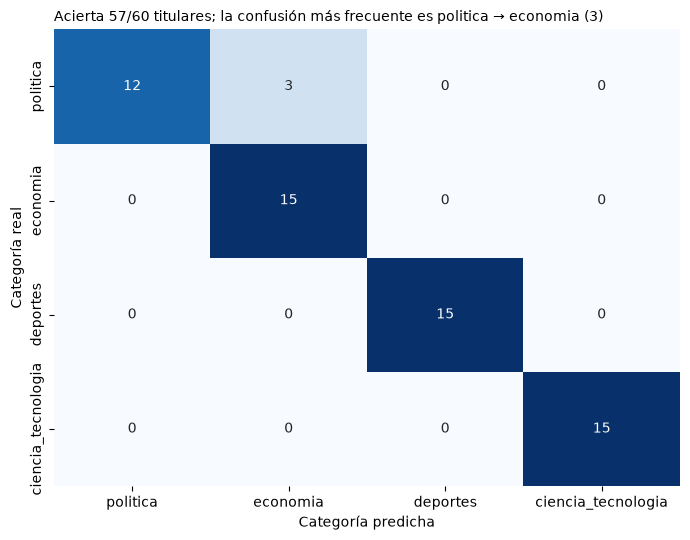

In [16]:
# PROCESO 6.2: Dibujar la matriz de confusión.
# Insumo: etiquetas reales y predichas del conjunto de prueba.
# Resultado: mapa de calor 4 × 4 y modelo/matriz_confusion.png.

# matplotlib: crea figuras estáticas, visibles en GitHub como imagen.
import matplotlib.pyplot as plt

# seaborn: dibuja la matriz como mapa de calor con los conteos en cada celda.
import seaborn as sns

# confusion_matrix: pares (real, predicha) → tabla 4 × 4 de conteos.
from sklearn.metrics import confusion_matrix

matriz = confusion_matrix(
    prueba["etiqueta"], prueba["pred_finetuned"], labels=CATEGORIAS
)

# Confusión más frecuente fuera de la diagonal, para el título.
fuera_diagonal = matriz.copy()
np.fill_diagonal(fuera_diagonal, 0)
fila, columna = np.unravel_index(fuera_diagonal.argmax(), fuera_diagonal.shape)
aciertos_ft = int(np.trace(matriz))

if fuera_diagonal.max() > 0:
    titulo = (f"Acierta {aciertos_ft}/{len(prueba)} titulares; la confusión más "
              f"frecuente es {CATEGORIAS[fila]} → {CATEGORIAS[columna]} "
              f"({fuera_diagonal.max()})")
else:
    titulo = f"Acierta los {len(prueba)} titulares de prueba"

figura, eje = plt.subplots(figsize=(7, 5.5))
sns.heatmap(
    matriz, annot=True, fmt="d", cmap="Blues", cbar=False,
    xticklabels=CATEGORIAS, yticklabels=CATEGORIAS, ax=eje
)
eje.set_xlabel("Categoría predicha")
eje.set_ylabel("Categoría real")
eje.set_title(titulo, fontsize=10, loc="left")
plt.tight_layout()
plt.savefig(carpeta_modelo / "matriz_confusion.png", dpi=120)
plt.show()

In [17]:
# PROCESO 6.3: Identificar la mejor y la peor categoría.
# Insumo: predicciones del conjunto de prueba.
# Resultado: F1 por categoría y titulares mal clasificados.

# f1_score(average=None): un F1 por categoría en lugar del promedio.
f1_por_categoria = pd.Series(
    f1_score(prueba["etiqueta"], prueba["pred_finetuned"],
             labels=CATEGORIAS, average=None, zero_division=0),
    index=CATEGORIAS, name="f1"
).sort_values(ascending=False)

print("F1 por categoría (prueba):")
print(f1_por_categoria.round(3))
print(f"\nMejor: {f1_por_categoria.index[0]} | Peor: {f1_por_categoria.index[-1]}")

errores_ft = prueba.loc[
    prueba["etiqueta"] != prueba["pred_finetuned"],
    ["titular", "etiqueta", "pred_finetuned"]
]
print(f"\nTitulares mal clasificados: {len(errores_ft)}")
with pd.option_context("display.max_colwidth", None):
    display(errores_ft)

F1 por categoría (prueba):
ciencia_tecnologia    1.000
deportes              1.000
economia              0.909
politica              0.889
Name: f1, dtype: float64

Mejor: ciencia_tecnologia | Peor: politica

Titulares mal clasificados: 3


,titular,etiqueta,pred_finetuned
25,Expertos señalan que pedido de facultades en relación a la DINI tiene tinte político,politica,economia
41,Minería ilegal elevó 8 veces la demanda de combustible,politica,economia
57,Fracasó estrategia del estudio de abogados al que López Aliaga pagó S/97.5 millones,politica,economia


### Reflexión por categoría

- **Mejor desempeño: deportes y ciencia_tecnologia (F1 = 1,000).** Deportes tiene un vocabulario casi
  exclusivo: clubes (*Universitario*, *Alianza Lima*, *Barcelona*), competencias (*Liga 1*,
  *Copa Libertadores*, *Champions*) y verbos de resultado (*vence*, *goleó*). Los titulares de ciencia
  son los más largos (mediana de 120 caracteres) y narrativos, con marcadores propios:
  *científicos*, *descubren*, *estudio*, *especies*.
- **Peor desempeño: politica (F1 = 0,889; recall = 0,80).** Su precisión es perfecta, pero 3 de sus 15
  titulares de prueba se clasificaron como economía:
  - "Minería ilegal elevó 8 veces la demanda de combustible"
  - "Fracasó estrategia del estudio de abogados al que López Aliaga pagó S/97.5 millones"
  - "Expertos señalan que pedido de facultades en relación a la DINI tiene tinte político"

  Los tres usan vocabulario económico (montos en soles, combustible, minería) en noticias que el diario
  publica en Política. El tema "pedido de facultades" aparece en ambas secciones: por ejemplo,
  "Facultades legislativas: GEPS cuestiona pedido del Ejecutivo…" está en Economía.
- **Confusión más frecuente: politica → economia (3 casos).** No es solo un error del modelo: la etiqueta
  es la sección editorial y no el tema. Un mismo hecho (gasto público, minería ilegal) puede publicarse
  en cualquiera de las dos secciones, y el titular no siempre muestra el ángulo político.

## Proceso 7: Comparativa y decisión

Los tres modelos se comparan sobre **los mismos 40 titulares de prueba** usados en el
zero-shot. El LLM y el modelo fine-tuned se evalúan además sobre los 60 de prueba.
La latencia se midió titular por titular en CPU, como en el probador del dashboard.

In [18]:
# PROCESO 7.1: Construir la tabla comparativa.
# Insumos: predicciones y latencias de los tres modelos.
# Resultado: tabla comparativa y modelo/comparativa.csv.

# merge(): muestra de 40 + predicciones de cada modelo → una fila por titular con las tres.
comparacion_40 = (
    muestra_zs[["titular", "etiqueta", "pred_zero_shot"]]
    .merge(etiquetas_llm[["titular", "etiqueta_llm"]], on="titular")
    .merge(prueba[["titular", "pred_finetuned"]], on="titular")
)


def metricas_40(columna):
    """Columna de predicciones → (accuracy, F1 macro) sobre los 40 titulares comunes."""
    return (
        accuracy_score(comparacion_40["etiqueta"], comparacion_40[columna]),
        f1_score(comparacion_40["etiqueta"], comparacion_40[columna], average="macro"),
    )


acc40_llm, f140_llm = metricas_40("etiqueta_llm")
acc40_ft, f140_ft = metricas_40("pred_finetuned")

comparativa = pd.DataFrame([
    {
        "modelo": "Zero-shot (NLI)",
        "id_hugging_face": MODELO_ZERO_SHOT,
        "entrenamiento_propio": "Ninguno",
        "parametros_millones": parametros_zs / 1e6,
        "accuracy_40": acc_zs, "f1_macro_40": f1_zs,
        "accuracy_test60": np.nan, "f1_macro_test60": np.nan,
        "latencia_ms": latencia_zs,
    },
    {
        "modelo": "LLM débil (Qwen local)",
        "id_hugging_face": MODELO_LLM,
        "entrenamiento_propio": "Ninguno (prompt)",
        "parametros_millones": parametros_llm / 1e6,
        "accuracy_40": acc40_llm, "f1_macro_40": f140_llm,
        "accuracy_test60": acc_llm_test, "f1_macro_test60": f1_llm_test,
        "latencia_ms": latencia_llm,
    },
    {
        "modelo": "Transformer fine-tuned",
        "id_hugging_face": MODELO_BASE,
        "entrenamiento_propio": f"{len(entrenamiento)} titulares, 3 épocas "
                                f"({minutos_entrenamiento:.1f} min CPU)",
        "parametros_millones": parametros_ft / 1e6,
        "accuracy_40": acc40_ft, "f1_macro_40": f140_ft,
        "accuracy_test60": acc_ft, "f1_macro_test60": f1_ft,
        "latencia_ms": latencia_ft,
    },
])

comparativa.to_csv(
    carpeta_modelo / "comparativa.csv", index=False, encoding="utf-8-sig"
)
display(comparativa.round(3))

,modelo,id_hugging_face,entrenamiento_propio,parametros_millones,accuracy_40,f1_macro_40,accuracy_test60,f1_macro_test60,latencia_ms
0,Zero-shot (NLI),Recognai/bert-base-spanish-wwm-cased-xnli,Ninguno,109.853,0.650,0.639,NaN,NaN,169.150
1,LLM débil (Qwen local),Qwen/Qwen2.5-1.5B-Instruct,Ninguno (prompt),1543.714,0.800,0.806,0.767,0.768,3157.566
2,Transformer fine-tuned,distilbert/distilbert-base-multilingual-cased,"280 titulares, 3 épocas (1.4 min CPU)",135.328,0.975,0.975,0.950,0.949,21.058


In [27]:
# PROCESO 7.2: Guardar las métricas y probar el modelo como lo hará el dashboard.
# Insumo: resultados de los procesos 3 a 6.
# Resultado: modelo/metricas.json y predicción de titulares nuevos.

metricas = {
    "f1_macro_test": round(f1_ft, 4),
    "accuracy_test": round(acc_ft, 4),
    "f1_macro_zero_shot_40": round(f1_zs, 4),
    "accuracy_zero_shot_40": round(acc_zs, 4),
    "f1_macro_llm_test": round(f1_llm_test, 4),
    "acuerdo_llm_humano": acuerdo_llm_humano,
    "aciertos_auditoria": aciertos_auditoria,
    "n_entrenamiento": len(entrenamiento),
    "n_validacion": len(validacion),
    "n_prueba": len(prueba),
    "modelo_base": MODELO_BASE,
    "modelo_llm": MODELO_LLM,
    "modelo_zero_shot": MODELO_ZERO_SHOT,
    "fecha": date.today().isoformat(),
}

with open(carpeta_modelo / "metricas.json", "w", encoding="utf-8") as archivo:
    json.dump(metricas, archivo, ensure_ascii=False, indent=2)

print(json.dumps(metricas, ensure_ascii=False, indent=2))

# Titulares inventados: comprueban que el modelo guardado responde como en app.py.
titulares_nuevos = [
    "Congreso debate nueva ley de reforma electoral",
    "El dólar cierra a la baja y la bolsa limeña gana 2 %",
    "Alianza Lima vence a Sporting Cristal en el clásico",
    "Científicos descubren un nuevo planeta similar a la Tierra",
]
for titular in titulares_nuevos:
    resultado = clasificador_final(titular)[0]
    print(f"{resultado['label']:>20} ({resultado['score']:.0%})  {titular}")

if acuerdo_llm_humano is None:
    print("\nFALTA completar la auditoría (Proceso 4.5) y volver a ejecutar esta celda.")
else:
    print("\nPara el comentario de entrega:")
    print(f"F1 macro test: {f1_ft:.3f} | Zero-shot F1 macro: {f1_zs:.3f} | "
          f"Acuerdo LLM–humano: {aciertos_auditoria}/20")

{
  "f1_macro_test": 0.9495,
  "accuracy_test": 0.95,
  "f1_macro_zero_shot_40": 0.6391,
  "accuracy_zero_shot_40": 0.65,
  "f1_macro_llm_test": 0.7679,
  "acuerdo_llm_humano": 0.85,
  "aciertos_auditoria": 17,
  "n_entrenamiento": 280,
  "n_validacion": 60,
  "n_prueba": 60,
  "modelo_base": "distilbert/distilbert-base-multilingual-cased",
  "modelo_llm": "Qwen/Qwen2.5-1.5B-Instruct",
  "modelo_zero_shot": "Recognai/bert-base-spanish-wwm-cased-xnli",
  "fecha": "2026-10-18"
}
            politica (97%)  Congreso debate nueva ley de reforma electoral
            economia (98%)  El dólar cierra a la baja y la bolsa limeña gana 2 %
            deportes (99%)  Alianza Lima vence a Sporting Cristal en el clásico
  ciencia_tecnologia (98%)  Científicos descubren un nuevo planeta similar a la Tierra

Para el comentario de entrega:
F1 macro test: 0.949 | Zero-shot F1 macro: 0.639 | Acuerdo LLM–humano: 17/20


### Decisión: ¿qué modelo usar en producción?

| Criterio | Zero-shot | LLM débil | Fine-tuned |
|---|---|---|---|
| F1 macro (40 titulares comunes) | 0,639 | 0,806 | **0,975** |
| F1 macro (test, 60 titulares) | — | 0,768 | **0,949** |
| Costo computacional | 110 M parámetros, sin entrenamiento | 1 544 M parámetros (~6 GB de RAM); unos 24 min para etiquetar 400 titulares en CPU | 135 M parámetros; 1,4 min de entrenamiento en CPU |
| Latencia (ms por titular, CPU) | 169 | 3 158 | **21** |

**Decisión: el Transformer fine-tuned.** Tiene el mayor F1 macro (0,949 en test frente a 0,768 del LLM),
responde unas 150 veces más rápido que el LLM (21 ms frente a 3,2 s) y, con 135 M parámetros, corre en
una laptop sin GPU ni API externa, sin costo por consulta. Su costo es que necesita etiquetas, aunque
280 titulares bastaron.

Los otros dos modelos siguen siendo útiles:
- **LLM:** como etiquetador débil fuera de línea, para ampliar la base con noticias nuevas. Su acuerdo
  con la auditoría humana (17/20) y con las secciones (85,5 %) indica que sus etiquetas necesitan
  revisión. Su confianza promedio baja de 0,94 a 0,71 cuando discrepa, lo que sirve para priorizar
  qué revisar.
- **Zero-shot:** para arrancar cuando no existe ninguna etiqueta o al agregar una categoría nueva. Es el
  piso (0,639) que el modelo entrenado supera por 0,31.